# Navigating the Cost Landscape 

In this notebook, we illustrate the landscape of the cost function and the paths that our optimization software chooses to take when navigating its way to the minimum.

In [1]:
import pennylane as qml
from pennylane import numpy as qnp
from matplotlib import pyplot as plt

import pennylane_kinesis as pk

An exception of type FileNotFoundException occurred. Arguments:
("Unable to find assembly 'Thorlabs.MotionControl.IntegratedStepperMotorsCLI'.",)

An error occured while importing pythonnet, time tagger, or kinesis software
setting `_TEST_MODE=True`


## Setting Up the Cost Function

To simulate the optical system, we use our custom `"kinesis.simulator"` device.
The simulator considers a finite shot setting where the number of shots is subjected to poissonian statistics.

In our circuit, the $|0\rangle$ state is prepared then a HWP and QWP are applied sequentially, $H(\theta)$ and $Q(\phi)$ respectively. To model noise and other transformations, we allow for either rotational noise, or arbitrary unitary noise. The noise model is static.

We parameterize the HWP angle using $\theta$ and the QWP angle using $\phi$. The cost function takes the form

$$
Cost(\theta, \phi) = \min_{\theta, \phi} P(|1\rangle|\theta,\phi) = \min_{\theta, \phi} |\langle 1| U Q(\phi) H(\theta) |0\rangle|^2
$$

where $U$ is the system noise. Intuitively, our goal is to minimize the probability of seeing the $|1\rangle$, *i.e.*, the same state is detected as input into the system. To achieve this goal, we ideally need $U^\dagger = Q(\phi) H(\theta)$.

In [2]:
kinesis_sim_dev = qml.device("kinesis.simulator", wires=[0], shots=10000)


def cost_fn(dev=kinesis_sim_dev, arb_settings=[], rot_settings=[]):
    @qml.qnode(dev, diff_method="parameter-shift")
    def circuit(settings):
        theta, phi = settings
        pk.HWPRotStage(theta, wires=dev.wires[0])
        pk.QWPRotStage(phi, wires=dev.wires[0])

        if arb_settings:
            qml.ArbitraryUnitary(arb_settings, wires=[dev.wires[0]])

        if rot_settings:
            qml.Rot(*rot_settings, wires=dev.wires[0])

        return qml.expval(qml.Projector([1], wires=dev.wires[0]))

    return circuit

## Optimizing the Cost Function

We aim to illustrate the path our gradient descent routine traverses.
This is done by simply by running a gradient descent optimization and recording the settings in each optimization step.

In [3]:
def gradient_descent_trajectory(
    cost, init_settings, theta_period=qnp.pi / 2, phi_period=qnp.pi, step_size=0.1, num_steps=12
):
    opt_dict = pk.optimize(
        cost,
        init_settings,
        step_size=0.1,
        num_steps=12,
        filepath="./data/cost_periodicity_analysis/",
        domain_periods=[theta_period, phi_period],
    )

    theta_settings = []
    phi_settings = []
    for settings in opt_dict["settings_history"]:
        theta_settings += [settings[0]]
        phi_settings += [settings[1]]

    return (theta_settings, phi_settings, opt_dict["cost_vals"])

## Plotting the Cost Function

To illustrate the cost function and our optimization trajectory, we create a helper function to make an informative plot as we explore different noise models.

In [4]:
def plot_cost_contour(title, cost, theta_set, phi_set, opt_results=None):
    data_dict = pk.scan_two_param_fn(cost, theta_set, phi_set)

    fig, ax = plt.subplots()
    plt.grid()
    CS = ax.contour(data_dict["x_grid"], data_dict["y_grid"], data_dict["z_grid"])
    ax.clabel(CS, inline=True, fontsize=10)
    ax.set_title(title)
    ax.set_xlabel(r"HWP Angle ($\theta$ Radians)")
    ax.set_ylabel(r"QWP Angle ($\phi$ Radians)")

    if opt_results:
        ax.plot(*opt_results[:2], marker="o", label="Gradient Descent")
        ax.plot(opt_results[0][0], opt_results[1][0], "rx", markersize=8, label="Starting Point")
        ax.plot(
            opt_results[0][-1],
            opt_results[1][-1],
            color="lime",
            marker="v",
            linestyle="",
            markersize=8,
            label="Ending Point",
        )

        plt.legend()

    plt.show()

    return data_dict["x_grid"], data_dict["y_grid"], data_dict["z_grid"]

## Noiseless Case

In the following example we do not include any unitary transformations other than the HWP and QWP rotational stages.
Our goal is to investigate the periodicity of the cost function with respect to the wave plate parameters, $\theta$ and $\phi$.

We begin by plotting over the region $\theta,\phi \in [0,2\pi]$.
We find a nice tiling that shows an invariance to phase shifts of $\pi/2$ radians for both $\theta$ and $\phi$.

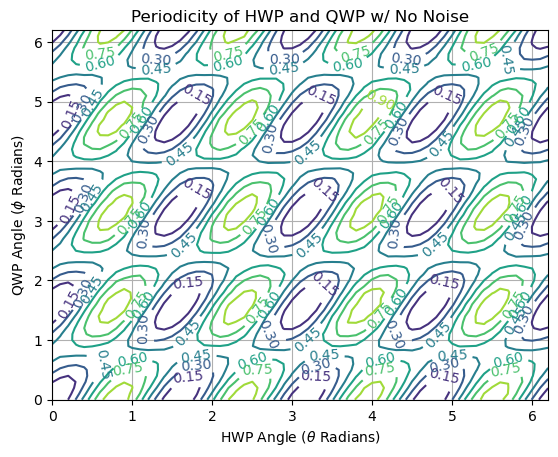

In [5]:
title = "Periodicity of HWP and QWP w/ No Noise"
cost = cost_fn()
theta_set = qnp.arange(0, 2 * qnp.pi, 0.1)
phi_set = qnp.arange(0, 2 * qnp.pi, 0.1)

plot_cost_contour(title, cost, theta_set, phi_set);

Next, we plot a single period with $\theta,\phi \in [0,\pi/2]$.
We then perform a gradient descent optimization starting near a peak and traversing to a minimum while restricting the settings to the defined domain.
We find that a sensible path is traversed from maximum to minimum.

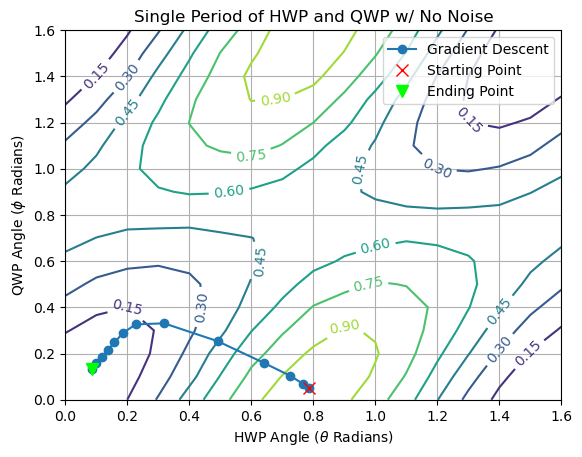

In [6]:
title = "Single Period of HWP and QWP w/ No Noise"
cost = cost_fn()
theta_set = qnp.arange(0, qnp.pi / 2 + 0.1, 0.1)
phi_set = qnp.arange(0, qnp.pi / 2 + 0.1, 0.1)

opt_results = gradient_descent_trajectory(
    cost, qnp.array([qnp.pi / 4, 0.05], requires_grad=True), phi_period=qnp.pi / 2
)


plot_cost_contour(title, cost, theta_set, phi_set, opt_results=opt_results);

## Cost Landscape with Rotational Noise

We now introduce some rotational noise.
An interesting feature is that the tiling changes as some peaks start to "merge".
In this case, we find $\theta$ to be invariant with respect to phase shifts of $\pi/2$ radians, but $\phi$ is invariant with respect to phase shifts of $\pi$ radians. 

noise unitary matrix :
[[ 0.78847323-0.53942356j -0.29404384+0.02950279j]
 [ 0.29404384+0.02950279j  0.78847323+0.53942356j]]


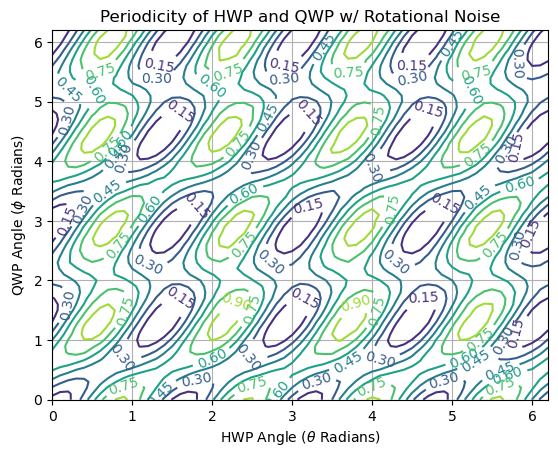

In [7]:
title = "Periodicity of HWP and QWP w/ Rotational Noise"
noise_settings = [0.5, 0.6, 0.7]
cost = cost_fn(rot_settings=noise_settings)
theta_set = qnp.arange(0, 2 * qnp.pi, 0.1)
phi_set = qnp.arange(0, 2 * qnp.pi, 0.1)

print("noise unitary matrix :")
print(qml.Rot(*noise_settings, wires=[0]).matrix())

plot_cost_contour(title, cost, theta_set, phi_set);

Next, we keep the noise model fixed, while we restrict our domain as $\theta\in[0,\pi/2]$ and $\phi \in [0, \pi]$ and plot the gradient descent trajectory from peak to valley.

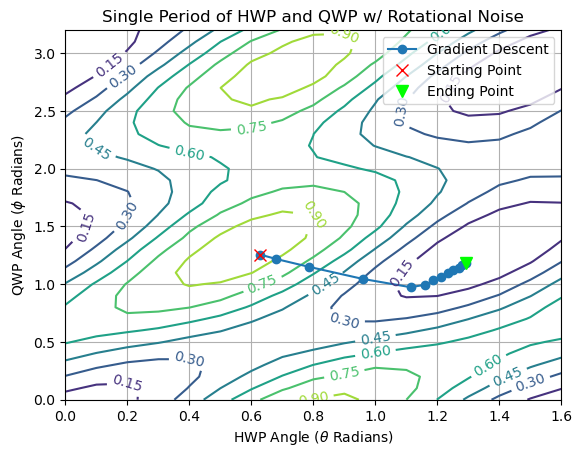

In [8]:
title = "Single Period of HWP and QWP w/ Rotational Noise"
noise_settings = [0.5, 0.6, 0.7]
cost = cost_fn(rot_settings=noise_settings)
theta_set = qnp.arange(0, qnp.pi / 2 + 0.1, 0.1)
phi_set = qnp.arange(0, qnp.pi + 0.1, 0.1)

opt_results = gradient_descent_trajectory(cost, qnp.array([qnp.pi / 5, qnp.pi / 2.5], requires_grad=True))

plot_cost_contour(title, cost, theta_set, phi_set, opt_results=opt_results);

## Cost Landscape with Respect to Arbitrary Unitary Noise

Finally, we investigate the effect of arbitrary unitary noise.
We find results to be comparable to the case of the unitary rotation

noise unitary matrix :
[[ 0.89458875-0.2487188j -0.35001887-0.1238415j]
 [ 0.35001887-0.1238415j  0.89458875+0.2487188j]]


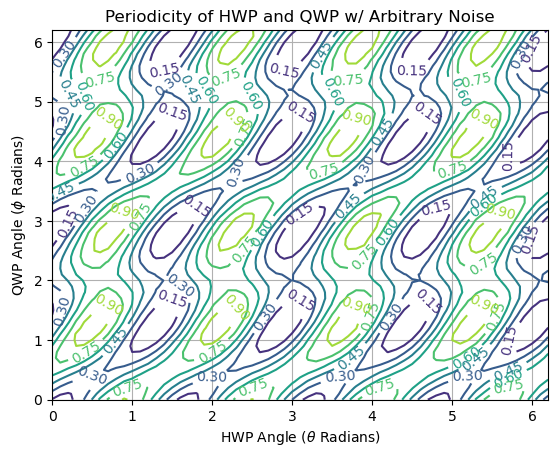

In [9]:
title = "Periodicity of HWP and QWP w/ Arbitrary Noise"
noise_settings = [0.5, 0.6, 0.7]
cost = cost_fn(arb_settings=noise_settings)
theta_set = qnp.arange(0, 2 * qnp.pi, 0.1)
phi_set = qnp.arange(0, 2 * qnp.pi, 0.1)

print("noise unitary matrix :")
print(qml.matrix(qml.ArbitraryUnitary(noise_settings, wires=[0])))

plot_cost_contour(title, cost, theta_set, phi_set);

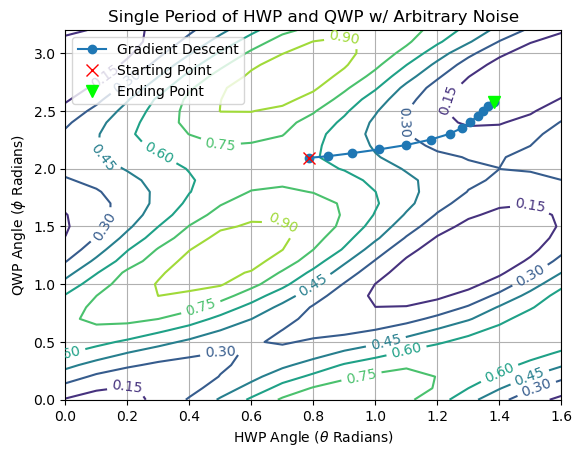

In [10]:
title = "Single Period of HWP and QWP w/ Arbitrary Noise"
cost = cost_fn(arb_settings=[0.5, 0.6, 0.7])
theta_set = qnp.arange(0, qnp.pi / 2 + 0.1, 0.1)
phi_set = qnp.arange(0, qnp.pi + 0.1, 0.1)

opt_results = gradient_descent_trajectory(cost, qnp.array([qnp.pi / 4, 2 * qnp.pi / 3], requires_grad=True))

plot_cost_contour(title, cost, theta_set, phi_set, opt_results=opt_results);

## Conclusions

Our illustrations show that we should be able to restrict our domain to $\theta\in[0,\pi/2]$ and $\phi\in[0,\pi]$ without ill effect in optimization.
It also seems like the optima in the regions $\phi\in[0,\pi/2]$ and $\phi\in[\pi/2,\pi]$ are the same.
Therefore, one could argue that there should always be a minimum in the region $\phi\in[0,\pi/2]$.
However, it is not immediately clear the exten to which deformations to the cost landscape can affect the optima.
The conservative path forward is to assume that $\phi\in[0,\pi]$ such that the whole cost landscape can be explored.
A stronger mathematical statement is required to affirm that we can indeed ignore the region $\phi\in[\pi/2,\pi]$.
